# Tuples, Image Processing, and Nested For Loops
## CS 65: Introduction to Computer Science I

## Today's Agenda

We're going to
* Introduce **tuples**, a data structure that is like lists, but we'll reflect on how they differ
* Learn how digital images are represented as a grid of pixels
* Use the `PIL` (Pillow) module and **nested for loops** to process images

### References

Think Python, Chapter 12 (especially Sections 12.1 and 12.3): https://greenteapress.com/thinkpython2/html/thinkpython2013.html

Python for Everybody, Chapter 10: https://www.py4e.com/html3/10-tuples

A Practical Introduction to Python Programming, Section 10.8 (Nested loops): https://www.brianheinold.net/python/python_book.html#section_nested_loops

A Practical Introduction to Python Programming, Section 16.2 (RGB colors): https://www.brianheinold.net/python/python_book.html#section_GUI1_colors

A Practical Introduction to Python Programming, Section 18.2 (The Python Imaging Library): https://www.brianheinold.net/python/python_book.html#section_GUI3_PIL

Pillow tutorial: https://pillow.readthedocs.io/en/stable/handbook/tutorial.html

Pillow `PixelAccess` reference: https://pillow.readthedocs.io/en/stable/reference/PixelAccess.html

## Tuple

It's an ordered collection like a list, but it uses parentheses ( ) instead of square brackets [ ]

In [ ]:
my_tuple = ("Eric",100,3.14)
print(my_tuple[0])

Eric


Except, tuples are _immutable_.
* You can't change an item in a tuple
* There are no methods like `append()`, `insert()`, `pop()`, or `remove()`

In [ ]:
my_tuple[1] = 200

TypeError: 'tuple' object does not support item assignment

## Purpose and benefits of tuples

Tuples are typically used when you have a grouping of related data that doesn't need to change; whereas, lists are typically used when you have a collection of a bunch of the same thing.

Tuples are also 
* Faster than lists
* Safer for things that shouldn't be changed
* Expected for working some modules and libraries (including working with images!)

In [ ]:
student_info = ("Stu Dent",100123456,"Computer Science")

student_list = [("Stu Dent",100123456,"Computer Science"), ("Elena Schmidt",100123457,"Math"), 
                ("Krystal Harmon",100123458,"Computer Science"), ("Marcos Hopkins",100123459,"Biology"), 
                ("Terry Richardson",100123460,"Political Science")]                                                    

Tuples can also be used to return more than one thing from a function.

In [ ]:
import csv

def parks_num_size(state):
    
    with open("nationalparks.csv") as npfile:
        parks_2d_list = list(csv.reader(npfile))
    
    num_parks_in_state = 0
    size_parks_in_state = 0
    
    for park in parks_2d_list:
        
        if park[1] == state:
            num_parks_in_state += 1
            size_parks_in_state += float(park[3])
    
    return (num_parks_in_state, size_parks_in_state)

parks_num_size("California")

(8, 2944702.3)

## Single-item tuples

You can have tuples with one thing in them, but you need to include a comma to tell Python it's a tuple and not just a parenthesized value.

In [ ]:
my_val = (100) 
print(my_val, type(my_val) )

100 <class 'int'>


In [ ]:
my_monuple = (100,)
print(my_monuple, type(my_monuple))

(100,) <class 'tuple'>


## Image Processing

How do tools like Photoshop manipulate images? Under the hood, it's all algorithms that work on the data of an image.

## Loading an image file in Python

Working with images in Python requires a module like the `PIL` (Python Imaging Library). To get this installed, you will need to install the `pillow` package. 

In Thonny, Tools $\rightarrow$ Manage Packages

<center>
<div>
<img src="images/pillowlibrary.png" width="600"/>
</div>
</center>

or 

`pip3 install pillow`

Here's some sample code for loading and displaying an image.

In [2]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    griff_image.show()

Demo: Let's see what this looks like in Thonny.

## Image Basics

Digital images are made of a grid of _picture elements_ called __pixels__.


<center>
<div>
<img src="images/griff.jpg" width="600"/>
</div>
</center>



<center>
<div>
<img src="images/pixels.png" width="500"/>
</div>
</center>

Each pixel is stored in the computer as three numbers: a red, a green, and a blue value representing the amount of each primary color of light needed to make that color. These values usually go between 0 and 255.


<center>
<div>
<img src="images/colorsliders.png" width="300"/>
</div>
</center>

_Why 255?_

Numbers are represented in a computer's memory in base-2, or binary notation which is made up of 0s and 1s (binary digits or __bits__) like 00100001 (33) or 11011100 (220). It's common to group bits into groups of 8 called a __byte__, and the biggest number you can represent with 8 bits is 11111111 (255).


## PIL representation of images

an image object in Python has several pieces of data and methods associated with it, and they can do a lot of sophisticated things. For the full reference on using the module, see https://pillow.readthedocs.io/en/stable/

However, we'll use just a few, simple things that will allow us to write custom code that manipulates images.

We can find the image's size with the `size` data attribute of our image, and we can load all the pixels into a variable using `load()`.

In [3]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    #griff_image.show()
    
    print(griff_image.size)

    pixels = griff_image.load()
    
    print(pixels[0,0])

(732, 412)
(196, 221, 243)


Notice: images store a lot of their information as tuples.

`size` is a tuple that tells you the number of pixel wide and tall an image is _(width,height)_

`pixel[0,0]` is the upper-left pixel in the image - the three values are the red, green, and blue amounts that make up the color stored there

`pixel[25,50]` is the pixel in the column 25 (the 26th column from the left) and row 50 (the 51st row from the top)

You can't change the tuple already in an image

In [4]:
pixels[25,50][0] = 100

TypeError: 'tuple' object does not support item assignment

but you can overwrite it with a whole new tuple

In [5]:
pixels[25,50] = (0,0,0) #overwriting pixel 100,200 with black
griff_image.show()

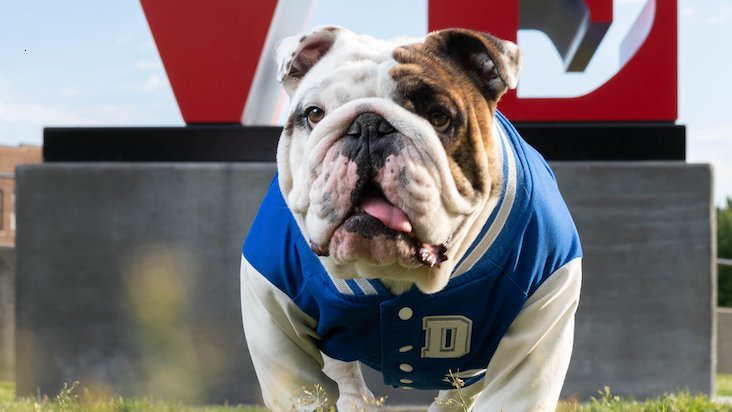

In [6]:
griff_image

## Exercise

Try loading another picture (your own photo, something from the Internet, etc.)

Print out its size and the pixel values in *all four corners of your image*

## Using loops for image processing

If I want to loop accross an entire row of an image, I could use `size[0]` (the width - the number of columns) to figure out how many iterations of the loops to run.

In [7]:
#loop through every column in the image
for p in range(griff_image.size[0]):
    pixels[p,50] = (0,0,0) #change the pixel at this column, row 50 to black
    
griff_image.show()

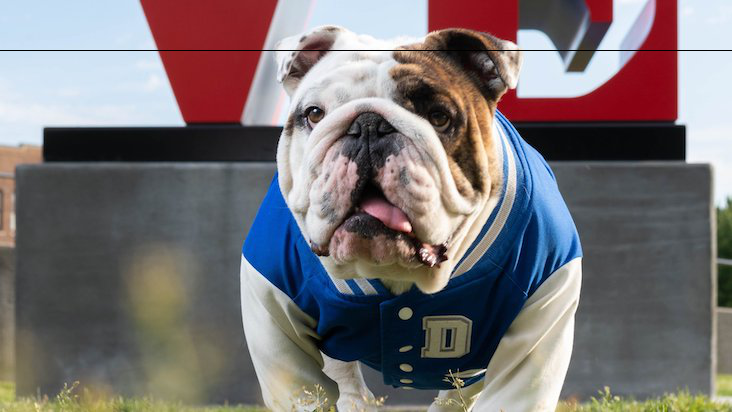

In [7]:
griff_image

and you could do a column similarly

In [8]:
#loop through every row in the image
for p in range(griff_image.size[1]):
    pixels[25,p] = (255,255,255) #change the pixel at this row, column 25 to white
    
griff_image.show()

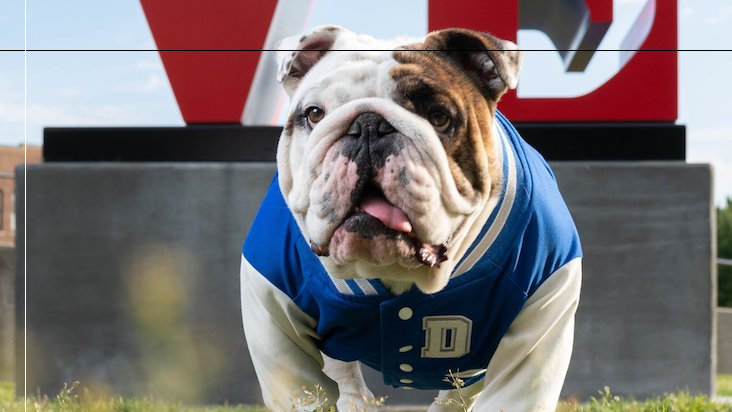

In [9]:
griff_image

## Saving the image

To save the image, run the `save()` method.

In [10]:
griff_image.save("griff_with_lines.jpg")

We should now have a new image saved in the same directory as our .py file.

If we wanted a thicker line, we might write

In [11]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    
for p in range(griff_image.size[0]):
    pixels[p,50] = (0,0,0) #change the pixel at this column, row 50 to black
    pixels[p,51] = (0,0,0)
    pixels[p,52] = (0,0,0)
    pixels[p,53] = (0,0,0)
    pixels[p,54] = (0,0,0)
    pixels[p,55] = (0,0,0)
    pixels[p,56] = (0,0,0)
    pixels[p,57] = (0,0,0)
    pixels[p,58] = (0,0,0)
    pixels[p,59] = (0,0,0)
    
griff_image.show()

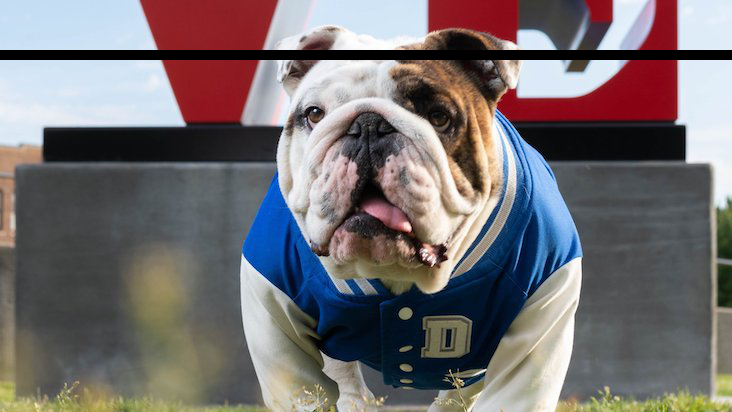

In [12]:
griff_image

Hopefully by now you're thinking "Hey, I could do that with another loop!"

And indeed you can! You can put a loop inside of another loop - this is called a __nested loop__.

In [12]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    
for p in range(griff_image.size[0]):
    for r in range(50,60):
        pixels[p,r] = (0,0,0)
    
    
    
griff_image.show()

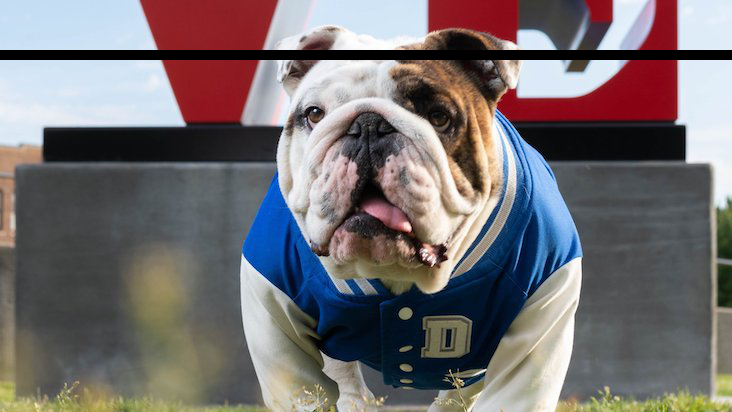

In [14]:
griff_image

The entire inner loop runs through all its iterations once for every iteration of the outer loop.

If the inner loop runs 10 iterations, and the outer loop runs 732 iterations, then the total number of pixel assignments is $732*10 = 7320$.

## Exercise

Make a thick line of another color somewhere different in your image.

## Looping through every pixel in the whole image

Outer loop: run through all the columns - there are `griff_image.size[0]` of them

Inner loop: run through all the rows - there are `griff_image.size[1]` of them

For this one, let's see what happens when we change all the pixels so that every color is the average of all three colors.

In [ ]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    
    
#in class we'll write a nested for loop here

griff_image.show()

In [13]:
#here is the solution
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    
for c in range(griff_image.size[0]):
    for r in range(griff_image.size[1]):
        red = pixels[c,r][0]
        green = pixels[c,r][1]
        blue = pixels[c,r][2]
        
        average_pixel_color = (red+green+blue)//3
        
        pixels[c,r] = (average_pixel_color,average_pixel_color,average_pixel_color)
    
    
    
griff_image.show()

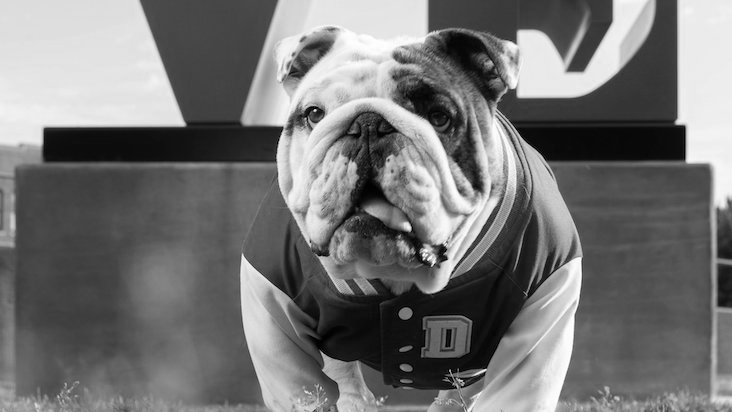

In [14]:
griff_image

You can play with the color values to make lots of other filters

In [15]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    
for c in range(griff_image.size[0]):
    for r in range(griff_image.size[1]):
        red = pixels[c,r][0]
        green = pixels[c,r][1]
        blue = pixels[c,r][2]
        
        
        pixels[c,r] = (red,green,blue*2)
    
    
    
griff_image.show()

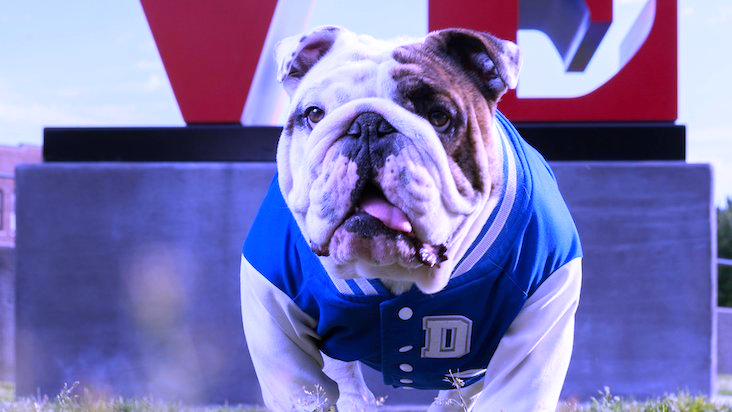

In [16]:
griff_image

## Flipping the image horizontally 

Let's talk about a transformation that requires us to move some pixels around.

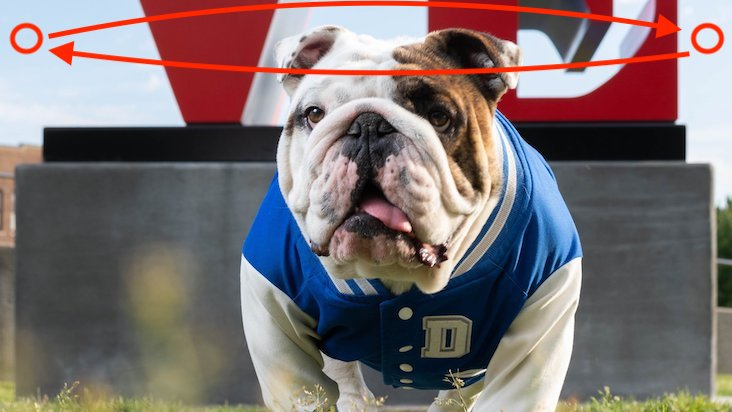

In [17]:
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    

#let's work on flipping the image horizontally
    
    
griff_image.show()

In [18]:
#horizontal flip solution
from PIL import Image

with Image.open("griff.jpg") as griff_image:
    pixels = griff_image.load()
    
for c in range(griff_image.size[0]//2):
    for r in range(griff_image.size[1]):

    
        leftside = pixels[griff_image.size[0]-1-c,r]
        pixels[griff_image.size[0]-1-c,r] = pixels[c,r]
        pixels[c,r] = leftside
    
    
griff_image.show()

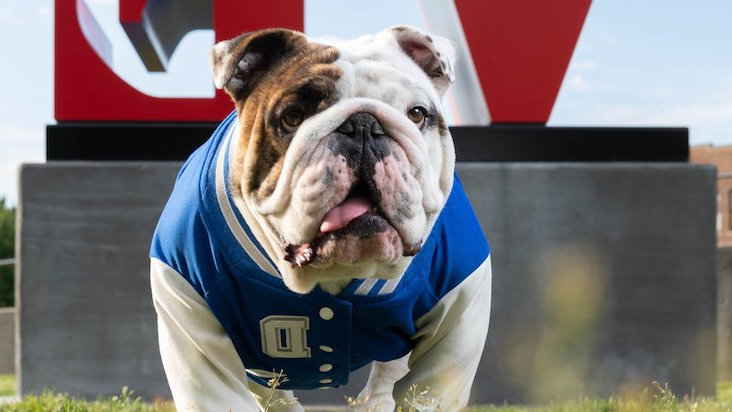

In [19]:
griff_image

## Exercise

Try changing this code so that it flips the image vertically instead of horizontally

## Exploration Exercise

Use nested `for` loops to apply some new kind of filter or effect to an image.  You only have to do one thing, and the difficulty level doesn't matter as long as you're using nested `for` loops. Here are some ideas:
* (Easy) Custom filter: Adjust the colors of your image to emphasize or de-emphasize each of the different color components to produce a neat effect.
* (Easy) Color-blindness simulation: Some individuals have trouble distinguishing some shades of red and green (these types of color blindess are called Protanopia and Deuteranopia). One way to crudely simulate what a person with one of these conditions would see is to average the red and green values for each pixel, but leave the blue value as it was originally.
* (Easy) Inverse filter: Change all color values to (255-original_value) to see the inverse colors of the image.
* (Medium) Classic filter: Look up the algorithm for a specific kind of color filter, and implement that (e.g., you can find a description of the Sepia algorithm here: https://dyclassroom.com/image-processing-project/how-to-convert-a-color-image-into-sepia-image )
* (Medium) Red-eye remover: find any red pixel (say, where the red color value is greater than the sum of the blue and green color values), and change these pixels to black.
* (Medium) Blurr effect: Make each pixel the average of the pixels around it (you can play around with how many pixels away you want to use in the average based on how blurry you want it to be)
* (Hard) Green-screen effect: Replace all green pixels of one photograph with the corresponding pixel from a different image. (For images, try searching http://images.google.com for something like "green screen movie set")
* (Hard) Pixel transformations: Pick a spot in the middle of the image, and move around the pixels to create a stretch, twist, bubble, etc. effect.